<a href="https://colab.research.google.com/github/tahta-id/Project-Google-Colab/blob/main/face_mask_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install kagglehub opencv-python numpy pandas tensorflow scikit-learn seaborn matplotlib

--- Mengunduh Dataset Face Mask via kagglehub ---
Using Colab cache for faster access to the 'face-mask-dataset' dataset.
Path to dataset files: /kaggle/input/face-mask-dataset
Total gambar valid yang siap diproses: 7553
Daftar Kategori: ['without_mask', 'with_mask']
Sampel citra wajah untuk Modul 1-3: /kaggle/input/face-mask-dataset/data/with_mask/with_mask_3326.jpg



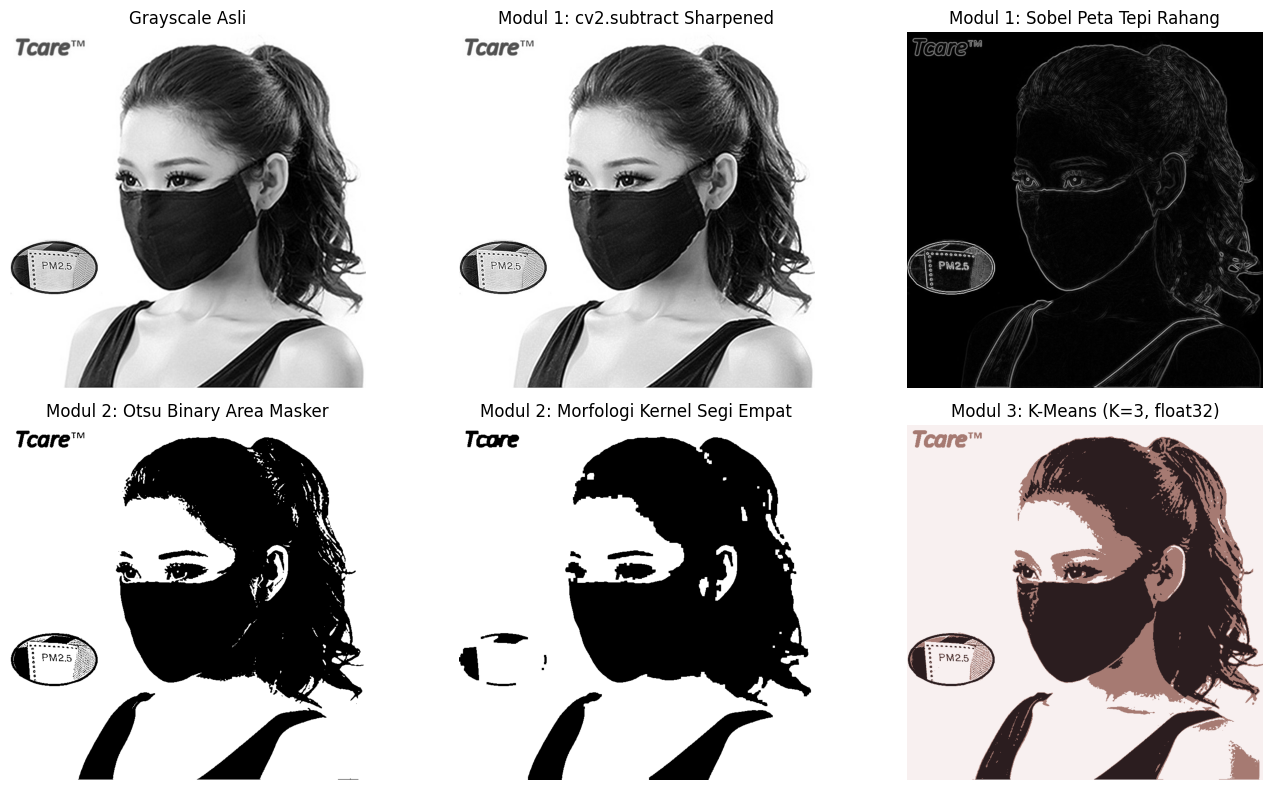


--- Modul 4: Menyiapkan Data Generator & Augmentasi CCTV ---
Found 6043 images belonging to 2 classes.
Found 1510 images belonging to 2 classes.
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

--- Melatih Model (Fine-Tuning 5 Epoch) ---
Epoch 1/5
 18/189 ━━━━━━━━━━━━━━━━━━━━ 3:30 1s/step - accuracy: 0.5101 - loss: 0.7161

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


189/189 ━━━━━━━━━━━━━━━━━━━━ 297s 1s/step - accuracy: 0.5166 - loss: 0.7093 - val_accuracy: 0.5066 - val_loss: 0.6966
Epoch 2/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 270s 1s/step - accuracy: 0.5161 - loss: 0.7072 - val_accuracy: 0.5060 - val_loss: 0.7069
Epoch 3/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 306s 2s/step - accuracy: 0.5304 - loss: 0.6978 - val_accuracy: 0.5053 - val_loss: 0.7033
Epoch 4/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 265s 1s/step - accuracy: 0.5317 - loss: 0.6984 - val_accuracy: 0.4914 - val_loss: 0.7021
Epoch 5/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 262s 1s/step - accuracy: 0.5338 - loss: 0.6944 - val_accuracy: 0.5046 - val_loss: 0.7106
48/48 ━━━━━━━━━━━━━━━━━━━━ 49s 961ms/step

================ CLASSIFICATION REPORT ================
              precision    recall  f1-score   support

   with_mask       0.41      0.01      0.02       745
without_mask       0.51      0.99      0.67       765

    accuracy                           0.50      1510
   macro avg       0.46      0.50      0.34      1510

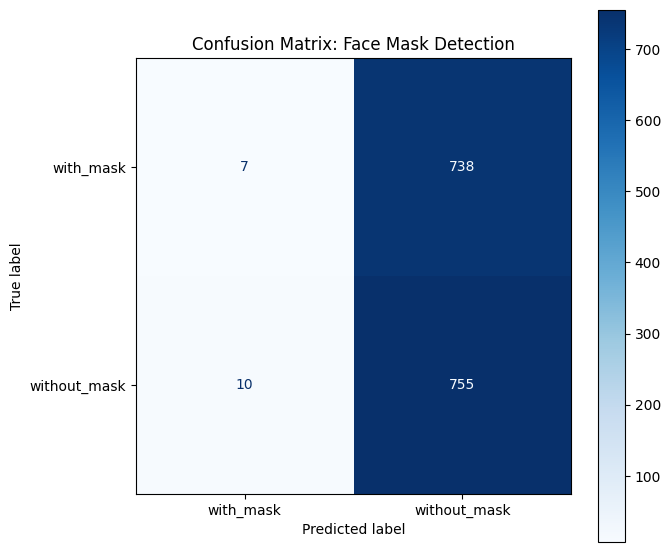

In [2]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import kagglehub

# =====================================================================
# 0. UNDUH DATASET FACE MASK MENGGUNAKAN KAGGLEHUB
# =====================================================================
print("--- Mengunduh Dataset Face Mask via kagglehub ---")
path = kagglehub.dataset_download("omkargurav/face-mask-dataset")
print("Path to dataset files:", path)

# 1. Cari semua file gambar (.png / .jpg / .jpeg) di seluruh subfolder dataset
image_files = glob.glob(os.path.join(path, "**", "*.png"), recursive=True) + \
              glob.glob(os.path.join(path, "**", "*.jpg"), recursive=True) + \
              glob.glob(os.path.join(path, "**", "*.jpeg"), recursive=True)

if not image_files:
    raise FileNotFoundError("Tidak ditemukan file gambar di dalam dataset Face Mask!")

# 2. Susun DataFrame berdasarkan folder kategori (with_mask & without_mask)
data = []
for img_path in image_files:
    class_name = os.path.basename(os.path.dirname(img_path))
    # Filter folder kategori yang relevan
    if class_name.lower() in ["with_mask", "without_mask"]:
        data.append({'file_path': img_path, 'class_str': class_name})

df = pd.DataFrame(data)

if df.empty:
    # Fallback jika nama direktori sedikit berbeda
    for img_path in image_files:
        parent_dir = os.path.basename(os.path.dirname(img_path))
        data.append({'file_path': img_path, 'class_str': parent_dir})
    df = pd.DataFrame(data)

print(f"Total gambar valid yang siap diproses: {len(df)}")
print(f"Daftar Kategori: {df['class_str'].unique().tolist()}")

# Ambil 1 sampel gambar beretiket dengan masker untuk demonstrasi Modul 1-3
sample_with_mask = df[df['class_str'].str.lower() == 'with_mask']
if not sample_with_mask.empty:
    sample_img_path = sample_with_mask['file_path'].iloc[0]
else:
    sample_img_path = df['file_path'].iloc[0]

print(f"Sampel citra wajah untuk Modul 1-3: {sample_img_path}\n")


# =====================================================================
# MODUL 1: Penajaman Frekuensi cv2.subtract & Sobel Gradien uint8
# =====================================================================
def modul_1_processing(image_path):
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        raise ValueError(f"Gagal memuat citra: {image_path}")

    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # 1. Pemburaman Gauss untuk mengekstrak frekuensi rendah
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # 2. Isolasi frekuensi tajam (detail) menggunakan cv2.subtract
    high_freq_detail = cv2.subtract(gray, blurred)

    # Tambahkan bobot detail frekuensi tajam ke gambar asal wajah
    sharpened = cv2.addWeighted(gray, 1.0, high_freq_detail, 1.5, 0)

    # 3. Peta tepi bertegangan matriks Sobel uint8
    sobel_x = cv2.Sobel(sharpened, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(sharpened, cv2.CV_64F, 0, 1, ksize=3)

    sobel_mag = cv2.magnitude(sobel_x, sobel_y)
    sobel_uint8 = cv2.normalize(sobel_mag, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

    return gray, sharpened, sobel_uint8


# =====================================================================
# MODUL 2: Ambang Otsu & Morfologi Kernel Segi Empat
# =====================================================================
def modul_2_processing(sharpened_img):
    # 1. Deteksi area masker pucat/pendaran terang dengan ambang Otsu
    _, otsu_thresh = cv2.threshold(sharpened_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # 2. Buat elemen pemroses bentuk segi empat (MORPH_RECT)
    kernel_rect = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))

    # Operasi closing dan opening untuk memuluskan batas pinggir masker dan dagu
    smooth_mask = cv2.morphologyEx(otsu_thresh, cv2.MORPH_CLOSE, kernel_rect)
    smooth_mask = cv2.morphologyEx(smooth_mask, cv2.MORPH_OPEN, kernel_rect)

    return otsu_thresh, smooth_mask


# =====================================================================
# MODUL 3: Klasterisasi K-Means 3 Warna Utama (np.float32)
# =====================================================================
def modul_3_processing(image_path):
    img_bgr = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # 1. Konversi himpunan piksel wajah manusia menjadi matriks 2D dengan tipe data np.float32
    pixel_values = img_rgb.reshape((-1, 3))
    pixel_values = np.float32(pixel_values)

    # 2. K-Means (K=3) untuk 3 pusat wilayah warna utama:
    # Pigmen kulit alami, spektrum masker kain, dan elemen latar belakang
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
    k = 3

    _, labels, centers = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

    centers = np.uint8(centers)
    segmented_data = centers[labels.flatten()]
    segmented_image = segmented_data.reshape(img_rgb.shape)

    return segmented_image


# =====================================================================
# MODUL 4: Model Augmentasi CCTV & Fine-Tuning 5 Epoch (With/Without Mask)
# =====================================================================
def modul_4_train_and_eval(dataset_path, img_size=(128, 128), batch_size=32, epochs_fine_tune=5):
    print("\n--- Modul 4: Menyiapkan Data Generator & Augmentasi CCTV ---")

    # Tentukan folder direktori dataset utama
    parent_dir = os.path.dirname(sample_img_path)
    data_dir = os.path.dirname(parent_dir)

    datagen = ImageDataGenerator(
        rescale=1./255,
        validation_split=0.2
    )

    # Flow data dua kategori folder (with_mask dan without_mask)
    train_gen = datagen.flow_from_directory(
        data_dir,
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        subset='training',
        shuffle=True
    )

    val_gen = datagen.flow_from_directory(
        data_dir,
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        subset='validation',
        shuffle=False
    )

    num_classes = len(train_gen.class_indices)

    # 1. Konstruksi Model dengan Lapisan Augmentasi Spasial (RandomZoom & RandomFlip)
    base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(img_size[0], img_size[1], 3))
    base_model.trainable = True

    # Bekukan seluruh layer awal kecuali 20 layer terdalam untuk fase Fine-Tuning
    for layer in base_model.layers[:-20]:
        layer.trainable = False

    inputs = layers.Input(shape=(img_size[0], img_size[1], 3))

    # Augmentasi orientasi miring rute kamera CCTV
    x = layers.RandomZoom(0.2)(inputs)
    x = layers.RandomFlip("horizontal")(x)

    x = base_model(x, training=True)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs, outputs)

    # Compile dengan optimizer Adam
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-5),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    print(f"\n--- Melatih Model (Fine-Tuning {epochs_fine_tune} Epoch) ---")
    model.fit(train_gen, validation_data=val_gen, epochs=epochs_fine_tune)

    # Evaluasi Prediksi
    val_gen.reset()
    y_pred_probs = model.predict(val_gen)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = val_gen.classes

    labels_map = {v: k for k, v in val_gen.class_indices.items()}
    class_names = [labels_map[i] for i in range(num_classes)]

    print("\n================ CLASSIFICATION REPORT ================")
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

    # Tampilkan ConfusionMatrixDisplay
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

    fig, ax = plt.subplots(figsize=(7, 6))
    disp.plot(cmap='Blues', ax=ax)
    plt.title('Confusion Matrix: Face Mask Detection')
    plt.tight_layout()
    plt.show()


# =====================================================================
# EKSEKUSI PIPELINE
# =====================================================================
if __name__ == "__main__":
    # Eksekusi Modul 1
    gray_img, sharpened_img, sobel_uint8 = modul_1_processing(sample_img_path)

    # Eksekusi Modul 2
    otsu_thresh, clean_mask = modul_2_processing(sharpened_img)

    # Eksekusi Modul 3
    kmeans_segmented = modul_3_processing(sample_img_path)

    # Visualisasi Hasil Modul 1 - 3
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes[0, 0].imshow(gray_img, cmap='gray')
    axes[0, 0].set_title('Grayscale Asli')

    axes[0, 1].imshow(sharpened_img, cmap='gray')
    axes[0, 1].set_title('Modul 1: cv2.subtract Sharpened')

    axes[0, 2].imshow(sobel_uint8, cmap='gray')
    axes[0, 2].set_title('Modul 1: Sobel Peta Tepi Rahang')

    axes[1, 0].imshow(otsu_thresh, cmap='gray')
    axes[1, 0].set_title('Modul 2: Otsu Binary Area Masker')

    axes[1, 1].imshow(clean_mask, cmap='gray')
    axes[1, 1].set_title('Modul 2: Morfologi Kernel Segi Empat')

    axes[1, 2].imshow(kmeans_segmented)
    axes[1, 2].set_title('Modul 3: K-Means (K=3, float32)')

    for ax in axes.ravel():
        ax.axis('off')
    plt.tight_layout()
    plt.show()

    # Eksekusi Modul 4 (Fine Tuning 5 Epoch)
    modul_4_train_and_eval(path, epochs_fine_tune=5)